# 01 — Data Collection & Exploration

This notebook covers spec §3.1 (data collection) and §3.2 (data exploration) for the
Washington State Electric Vehicle Population dataset. It **reads** `data/raw/` and does not
modify or save any data. Cleaning decisions are recorded in §3 as a plan for `src/cleaning.py`.

Cells marked ✍️ **TODO (team)** are for the group's own interpretation (spec §6: LLMs must not
write the analysis or conclusions).

In [1]:
import sys
sys.path.append("..")  # make src/ importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src.eda import (load_raw, parse_point, missing_report, outlier_summary,
                     label_collisions, utility_count, top_share, rare_categories,
                     PLACEHOLDER_ZERO_COLS, ID_LIKE_COLS)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Fixed colours: BEV = blue, PHEV = orange (same entity -> same colour in every plot)
TYPE_COLORS = {"BEV": "#2a78d6", "PHEV": "#eb6834"}
SEQ_COLOR = "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
})

## 1. Data collection


## 2. Data exploration

### 2.1 Overview: shape, row meaning, dtypes, duplicates

In [2]:
df = load_raw("../data/raw")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 177,866   Columns: 17


,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJYGDEE1L,King,Seattle,WA,98122.0,2020,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,291,0,37.0,125701579,POINT (-122.30839 47.610365),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
1,7SAYGDEE9P,Snohomish,Bothell,WA,98021.0,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,1.0,244285107,POINT (-122.179458 47.802589),PUGET SOUND ENERGY INC,5.306105e+10
2,5YJSA1E4XK,King,Seattle,WA,98109.0,2019,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,270,0,36.0,156773144,POINT (-122.34848 47.632405),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
3,5YJSA1E27G,King,Issaquah,WA,98027.0,2016,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,210,0,5.0,165103011,POINT (-122.03646 47.534065),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
4,5YJYGDEE5M,Kitsap,Suquamish,WA,98392.0,2021,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,23.0,205138552,POINT (-122.55717 47.733415),PUGET SOUND ENERGY INC,5.303594e+10


**Column dictionary.** The meanings below come from the data.wa.gov metadata; the dtypes and
examples come from the loaded file.

In [3]:
meaning = {
    "VIN (1-10)": "First 10 characters of the Vehicle Identification Number (make/model/year prefix)",
    "County": "County of the registered owner's address",
    "City": "City of the registered owner's address",
    "State": "State of the registered owner's address",
    "Postal Code": "5-digit ZIP code of the registered owner's address",
    "Model Year": "Model year of the vehicle (from the VIN)",
    "Make": "Manufacturer",
    "Model": "Model name",
    "Electric Vehicle Type": "BEV (all-electric) or PHEV (plug-in hybrid)",
    "Clean Alternative Fuel Vehicle (CAFV) Eligibility": "WA tax-exemption eligibility, based on fuel and electric range",
    "Electric Range": "All-electric range in miles (0 = not researched)",
    "Base MSRP": "Lowest manufacturer's suggested retail price for the model, USD (0 = not researched)",
    "Legislative District": "WA state legislative district of the owner's address",
    "DOL Vehicle ID": "DOL's unique vehicle identifier",
    "Vehicle Location": "Centroid of the owner's ZIP code as WKT 'POINT (lon lat)'",
    "Electric Utility": "Electric utility/utilities serving the address ('|'-separated when several)",
    "2020 Census Tract": "11-digit 2020 census tract GEOID (state+county+tract)",
}
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_null": df.isna().sum(),
    "example": df.iloc[0],
    "meaning": pd.Series(meaning),
})
overview

,dtype,n_unique,n_null,example,meaning
VIN (1-10),str,10830,0,5YJYGDEE1L,First 10 characters of the Vehicle Identificat...
County,str,196,5,King,County of the registered owner's address
City,str,723,5,Seattle,City of the registered owner's address
State,str,46,0,WA,State of the registered owner's address
Postal Code,float64,862,5,98122.0,5-digit ZIP code of the registered owner's add...
Model Year,int64,22,0,2020,Model year of the vehicle (from the VIN)
Make,str,40,0,TESLA,Manufacturer
Model,str,139,0,MODEL Y,Model name
Electric Vehicle Type,str,2,0,Battery Electric Vehicle (BEV),BEV (all-electric) or PHEV (plug-in hybrid)
Clean Alternative Fuel Vehicle (CAFV) Eligibility,str,3,0,Clean Alternative Fuel Vehicle Eligible,"WA tax-exemption eligibility, based on fuel an..."


In [4]:
n_full_dup = df.duplicated().sum()
n_id_dup = df["DOL Vehicle ID"].duplicated().sum()
n_vin_dup = df["VIN (1-10)"].duplicated(keep=False).sum()
n_empty_rows = df.isna().all(axis=1).sum()

print(f"Fully duplicated rows:         {n_full_dup:,}")
print(f"Duplicated DOL Vehicle ID:     {n_id_dup:,}")
print(f"Completely empty rows:         {n_empty_rows:,}")
print(f"Rows sharing a VIN (1-10):     {n_vin_dup:,}  "
      f"({df['VIN (1-10)'].nunique():,} distinct prefixes)")

Fully duplicated rows:         0
Duplicated DOL Vehicle ID:     0
Completely empty rows:         0
Rows sharing a VIN (1-10):     175,836  (10,830 distinct prefixes)


`VIN (1-10)` is only a VIN prefix, so many vehicles of the same make/model/year share one value.
The table below checks this: rows that share a prefix should agree on make, model and year.

In [5]:
vin_consistency = (df.groupby("VIN (1-10)")[["Make", "Model", "Model Year"]]
                     .nunique().gt(1).sum())
print("VIN prefixes mapping to >1 distinct value of:")
vin_consistency

VIN prefixes mapping to >1 distinct value of:


Make          0
Model         0
Model Year    0
dtype: int64

In [6]:
# ID-like columns are stored as float only because they contain NaN.
for col in ID_LIKE_COLS:
    s = df[col].dropna()
    print(f"{col:22s} dtype={df[col].dtype}  all-integer={bool((s % 1 == 0).all())}  "
          f"digits={sorted(int(d) for d in s.astype('int64').astype(str).str.len().unique())}")

Postal Code            dtype=float64  all-integer=True  digits=[4, 5]
Legislative District   dtype=float64  all-integer=True  digits=[1, 2]
2020 Census Tract      dtype=float64  all-integer=True  digits=[10, 11]


> ✍️ **TODO (team):** state what one row represents, which columns to drop or convert (e.g. ID-like floats
→ string codes, `Vehicle Location` → lon/lat), and whether any duplicates need removing. Justify
each choice.

### 2.2 Missing data

This covers explicit `NaN`s and also the **placeholder zeros** in `Electric Range` and `Base MSRP`,
which mean "not researched" rather than a measured 0.

In [7]:
miss = missing_report(df)
miss[(miss["n_null"] > 0) | (miss["n_placeholder_zero"] > 0)]

,n_null,pct_null,n_placeholder_zero,pct_placeholder_zero
Base MSRP,0,0.00,174522,98.12
Electric Range,0,0.00,91950,51.70
Legislative District,389,0.22,0,0.00
Vehicle Location,9,0.01,0,0.00
Electric Utility,5,0.00,0,0.00
County,5,0.00,0,0.00
City,5,0.00,0,0.00
Postal Code,5,0.00,0,0.00
2020 Census Tract,5,0.00,0,0.00


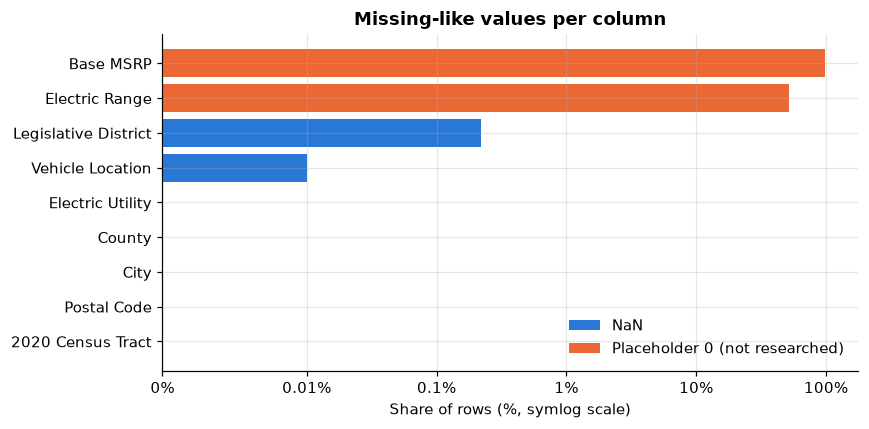

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_miss = miss[(miss["n_null"] > 0) | (miss["n_placeholder_zero"] > 0)].iloc[::-1]
ax.barh(plot_miss.index, plot_miss["pct_null"], color="#2a78d6", label="NaN")
ax.barh(plot_miss.index, plot_miss["pct_placeholder_zero"], left=plot_miss["pct_null"],
        color="#eb6834", label="Placeholder 0 (not researched)")
ax.set_xscale("symlog", linthresh=0.01)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_xlabel("Share of rows (%, symlog scale)")
ax.set_title("Missing-like values per column")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

**Missingness pattern.** Do the NaNs fall on the same rows, and are they linked to out-of-state registrations?

In [9]:
null_cols = miss.index[miss["n_null"] > 0].tolist()
null_mask = df[null_cols].isna()
print("Rows with >=1 NaN:", int(null_mask.any(axis=1).sum()))
print("\nCo-occurrence of NaNs (rows missing both):")
co = null_mask.astype(int).T @ null_mask.astype(int)
display(co)

out_of_state = df["State"].ne("WA")
print("NaN counts, WA vs out-of-state rows:")
display(null_mask.groupby(out_of_state.map({False: "WA", True: "Out of state"})).sum())

Rows with >=1 NaN: 393

Co-occurrence of NaNs (rows missing both):


,Legislative District,Vehicle Location,Electric Utility,County,City,Postal Code,2020 Census Tract
Legislative District,389,5,5,5,5,5,5
Vehicle Location,5,9,5,5,5,5,5
Electric Utility,5,5,5,5,5,5,5
County,5,5,5,5,5,5,5
City,5,5,5,5,5,5,5
Postal Code,5,5,5,5,5,5,5
2020 Census Tract,5,5,5,5,5,5,5


NaN counts, WA vs out-of-state rows:


,Legislative District,Vehicle Location,Electric Utility,County,City,Postal Code,2020 Census Tract
State,,,,,,,
Out of state,389,5,5,5,5,5,5
WA,0,4,0,0,0,0,0


In [10]:
# Placeholder zeros: are they linked to Model Year / vehicle type?
zero_range_by_year = (df.assign(range_zero=df["Electric Range"].eq(0))
                        .groupby("Model Year")["range_zero"].agg(["mean", "size"]))
zero_range_by_year["mean"] *= 100
zero_by_type = df.groupby("Electric Vehicle Type")[PLACEHOLDER_ZERO_COLS].apply(lambda g: g.eq(0).mean() * 100)
print("% placeholder zeros by EV type:")
display(zero_by_type.round(2))

print("CAFV eligibility vs Electric Range == 0:")
pd.crosstab(df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"], df["Electric Range"].eq(0),
            margins=True).rename(columns={False: "range > 0", True: "range == 0"})

% placeholder zeros by EV type:


,Electric Range,Base MSRP
Electric Vehicle Type,,
Battery Electric Vehicle (BEV),66.05,98.46
Plug-in Hybrid Electric Vehicle (PHEV),0.00,96.88


CAFV eligibility vs Electric Range == 0:


Electric Range,range > 0,range == 0,All
Clean Alternative Fuel Vehicle (CAFV) Eligibility,,,
Clean Alternative Fuel Vehicle Eligible,66331,0,66331
Eligibility unknown as battery range has not been researched,0,91950,91950
Not eligible due to low battery range,19585,0,19585
All,85916,91950,177866


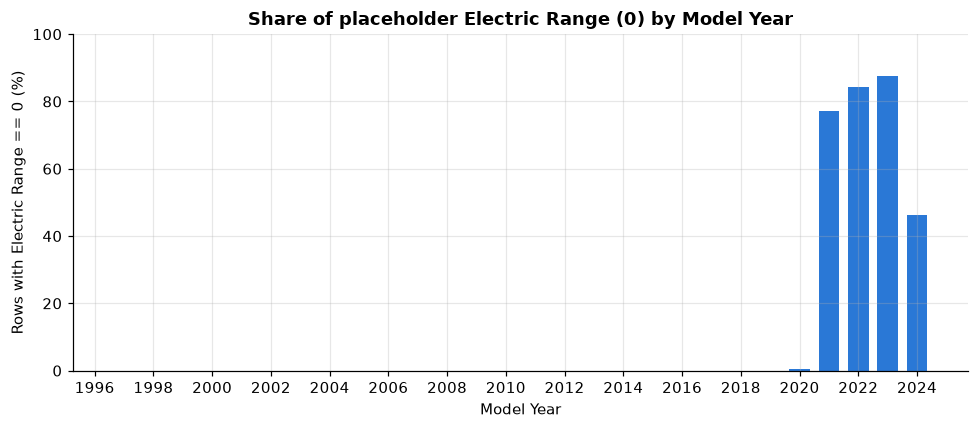

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(zero_range_by_year.index, zero_range_by_year["mean"], color=SEQ_COLOR, width=0.7)
ax.set_xlabel("Model Year")
ax.set_ylabel("Rows with Electric Range == 0 (%)")
ax.set_title("Share of placeholder Electric Range (0) by Model Year")
ax.set_ylim(0, 100)
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
plt.tight_layout()
plt.show()

> ✍️ **TODO (team):** describe the missingness pattern (random? concentrated in certain years, types or
out-of-state rows?), why the values are missing, and how you will handle each column (drop rows,
treat 0 as NaN, keep as a separate category, …).

### 2.3 Numerical columns

The real numerical measurements are `Model Year`, `Electric Range` and `Base MSRP`. `Postal Code`,
`Legislative District`, `2020 Census Tract` and `DOL Vehicle ID` are identifiers, so their
mean or std is meaningless. Range and MSRP are summarised **with and without** placeholder zeros.

In [12]:
num_summary = pd.DataFrame({
    "Model Year": outlier_summary(df["Model Year"]),
    "Electric Range (all)": outlier_summary(df["Electric Range"]),
    "Electric Range (>0)": outlier_summary(df.loc[df["Electric Range"] > 0, "Electric Range"]),
    "Base MSRP (all)": outlier_summary(df["Base MSRP"]),
    "Base MSRP (>0)": outlier_summary(df.loc[df["Base MSRP"] > 0, "Base MSRP"]),
}).T
num_summary.round(2)

,n,mean,median,std,skew,min,q1,q3,max,iqr_low_fence,iqr_high_fence,n_iqr_outliers,n_|z|>3
Model Year,177866.0,2020.52,2022.0,2.99,-1.14,1997.0,2019.0,2023.0,2024.0,2013.0,2029.0,2453.0,835.0
Electric Range (all),177866.0,58.84,0.0,91.98,1.45,0.0,0.0,75.0,337.0,-112.5,187.5,32541.0,76.0
Electric Range (>0),85916.0,121.82,84.0,99.22,0.45,6.0,32.0,215.0,337.0,-242.5,489.5,0.0,0.0
Base MSRP (all),177866.0,1073.11,0.0,8358.62,13.36,0.0,0.0,0.0,845000.0,0.0,0.0,3344.0,3344.0
Base MSRP (>0),3344.0,57078.25,59900.0,22795.52,12.86,31950.0,39995.0,69900.0,845000.0,-4862.5,114757.5,11.0,11.0


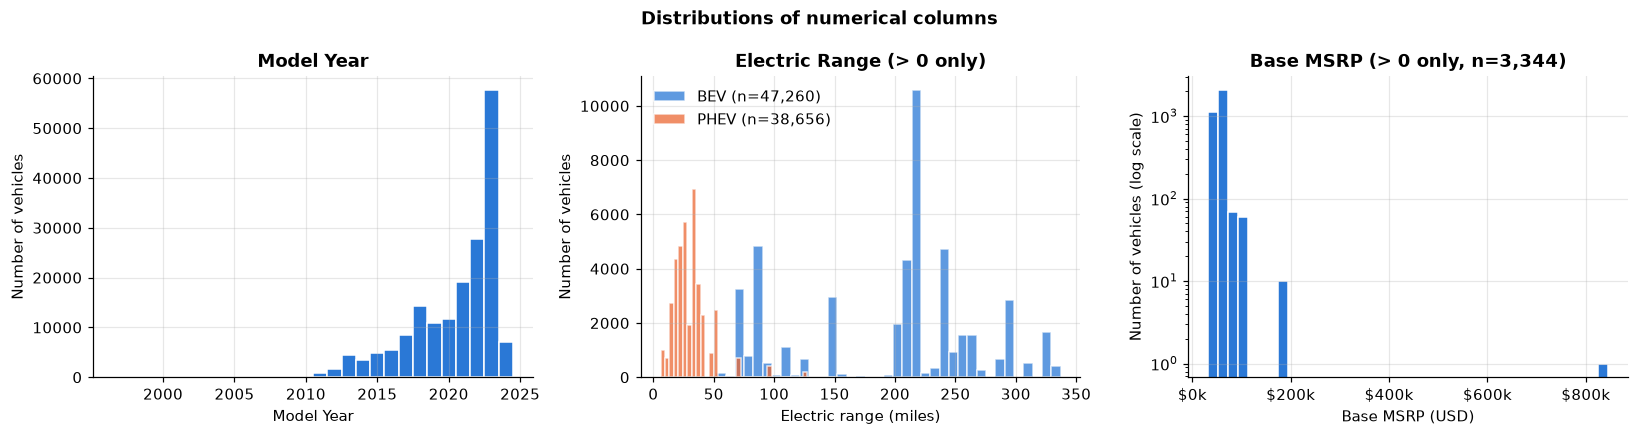

In [13]:
rng = df.loc[df["Electric Range"] > 0]
msrp = df.loc[df["Base MSRP"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["Model Year"], bins=np.arange(df["Model Year"].min(), df["Model Year"].max() + 2) - 0.5,
             color=SEQ_COLOR, edgecolor="white")
axes[0].set(title="Model Year", xlabel="Model Year", ylabel="Number of vehicles")

for t, c in TYPE_COLORS.items():
    sub = rng.loc[rng["Electric Vehicle Type"].str.contains(f"({t})", regex=False), "Electric Range"]
    axes[1].hist(sub, bins=40, alpha=0.75, color=c, label=f"{t} (n={len(sub):,})", edgecolor="white")
axes[1].set(title="Electric Range (> 0 only)", xlabel="Electric range (miles)", ylabel="Number of vehicles")
axes[1].legend(frameon=False)

axes[2].hist(msrp["Base MSRP"], bins=40, color=SEQ_COLOR, edgecolor="white")
axes[2].set_yscale("log")
axes[2].xaxis.set_major_locator(mticker.MultipleLocator(200_000))
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k"))
axes[2].set(title=f"Base MSRP (> 0 only, n={len(msrp):,})", xlabel="Base MSRP (USD)",
            ylabel="Number of vehicles (log scale)")

fig.suptitle("Distributions of numerical columns", fontweight="bold")
plt.tight_layout()
plt.show()

**Outliers.** Which vehicles lie outside the IQR fences? Are they real models or data errors?

In [14]:
hi_fence = num_summary.loc["Base MSRP (>0)", "iqr_high_fence"]
print(f"Base MSRP > IQR high fence (${hi_fence:,.0f}):")
display(msrp.loc[msrp["Base MSRP"] > hi_fence]
            .groupby(["Make", "Model", "Model Year"])["Base MSRP"].agg(["first", "size"])
            .sort_values("first", ascending=False))

lo_fence = num_summary.loc["Model Year", "iqr_low_fence"]
print(f"Model Year < IQR low fence ({lo_fence:.0f}):")
display(df.loc[df["Model Year"] < lo_fence].groupby(["Model Year", "Make", "Model"]).size()
          .rename("n").reset_index().sort_values("Model Year").head(20))

Base MSRP > IQR high fence ($114,758):


first  size
Make    Model    Model Year              
PORSCHE 918      2015        845000     1
        PANAMERA 2018        184400    10

Model Year < IQR low fence (2013):


,Model Year,Make,Model,n
0,1997,CHEVROLET,S-10 PICKUP,1
1,1998,FORD,RANGER,1
2,1999,FORD,RANGER,5
3,2000,FORD,RANGER,7
4,2002,TOYOTA,RAV4,2
5,2003,TOYOTA,RAV4,1
6,2008,TESLA,ROADSTER,20
7,2010,TESLA,ROADSTER,20
8,2010,WHEEGO ELECTRIC CARS,WHEEGO,3
9,2011,AZURE DYNAMICS,TRANSIT CONNECT ELECTRIC,5


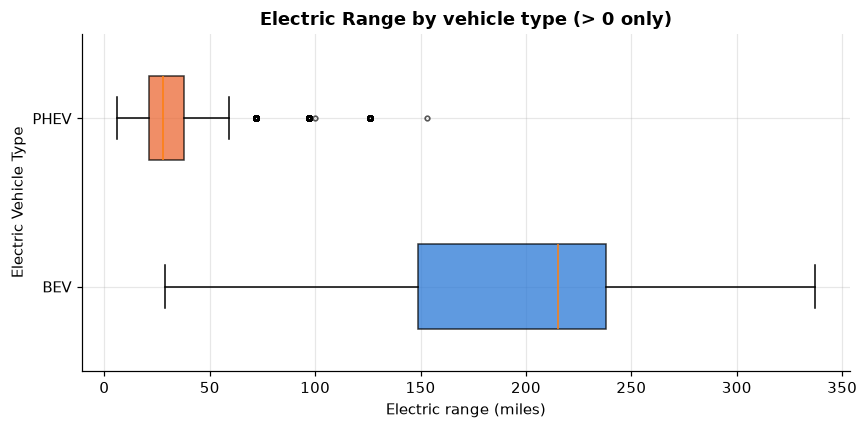

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [rng.loc[rng["Electric Vehicle Type"].str.contains(f"({t})", regex=False), "Electric Range"]
        for t in TYPE_COLORS]
bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.3))
for patch, c in zip(bp["boxes"], TYPE_COLORS.values()):
    patch.set_facecolor(c); patch.set_alpha(0.75)
ax.set_yticks([1, 2], list(TYPE_COLORS))
ax.set(title="Electric Range by vehicle type (> 0 only)", xlabel="Electric range (miles)",
       ylabel="Electric Vehicle Type")
plt.tight_layout()
plt.show()

> ✍️ **TODO (team):** for each numerical column: shape, centre and spread; are min/max plausible; are the
outliers genuine (e.g. luxury models, very old model years) or errors; how will you treat the
placeholder zeros.

### 2.4 Categorical columns

In [16]:
cat_cols = ["State", "County", "City", "Make", "Model", "Electric Vehicle Type",
            "Clean Alternative Fuel Vehicle (CAFV) Eligibility", "Electric Utility"]
cat_overview = pd.DataFrame({
    "n_unique": df[cat_cols].nunique(),
    "top": df[cat_cols].mode().iloc[0],
    "top_pct": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 2) for c in cat_cols],
    "n_rare_<0.1%": [len(rare_categories(df[c])) for c in cat_cols],
    "label_collisions": [len(label_collisions(df[c])) for c in cat_cols],
})
cat_overview

,n_unique,top,top_pct,n_rare_<0.1%,label_collisions
State,46,WA,99.78,45,0
County,196,King,52.14,165,0
City,723,Seattle,16.56,607,0
Make,40,TESLA,44.79,9,0
Model,139,MODEL Y,20.23,58,0
Electric Vehicle Type,2,Battery Electric Vehicle (BEV),78.27,0,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,3,Eligibility unknown as battery range has not b...,51.70,0,0
Electric Utility,76,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),37.10,39,0


`label_collisions` counts labels that differ only in case or whitespace (e.g. "Seattle" vs "SEATTLE"). Any collisions found are listed below.

In [17]:
for c in cat_cols:
    lc = label_collisions(df[c])
    if len(lc):
        print(c); display(lc)

In [18]:
print("State (top 10):")
display(top_share(df["State"], 10))
print("Electric Vehicle Type:")
display(top_share(df["Electric Vehicle Type"]))
print("CAFV eligibility:")
display(top_share(df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"]))

State (top 10):


,count,pct,cum_pct
State,,,
WA,177477,99.78,99.78
CA,101,0.06,99.84
VA,46,0.03,99.87
MD,31,0.02,99.89
TX,23,0.01,99.90
NC,16,0.01,99.91
IL,15,0.01,99.92
CO,12,0.01,99.93
AZ,10,0.01,99.94


Electric Vehicle Type:


,count,pct,cum_pct
Electric Vehicle Type,,,
Battery Electric Vehicle (BEV),139210,78.27,78.27
Plug-in Hybrid Electric Vehicle (PHEV),38656,21.73,100.00


CAFV eligibility:


,count,pct,cum_pct
Clean Alternative Fuel Vehicle (CAFV) Eligibility,,,
Eligibility unknown as battery range has not been researched,91950,51.70,51.70
Clean Alternative Fuel Vehicle Eligible,66331,37.29,88.99
Not eligible due to low battery range,19585,11.01,100.00


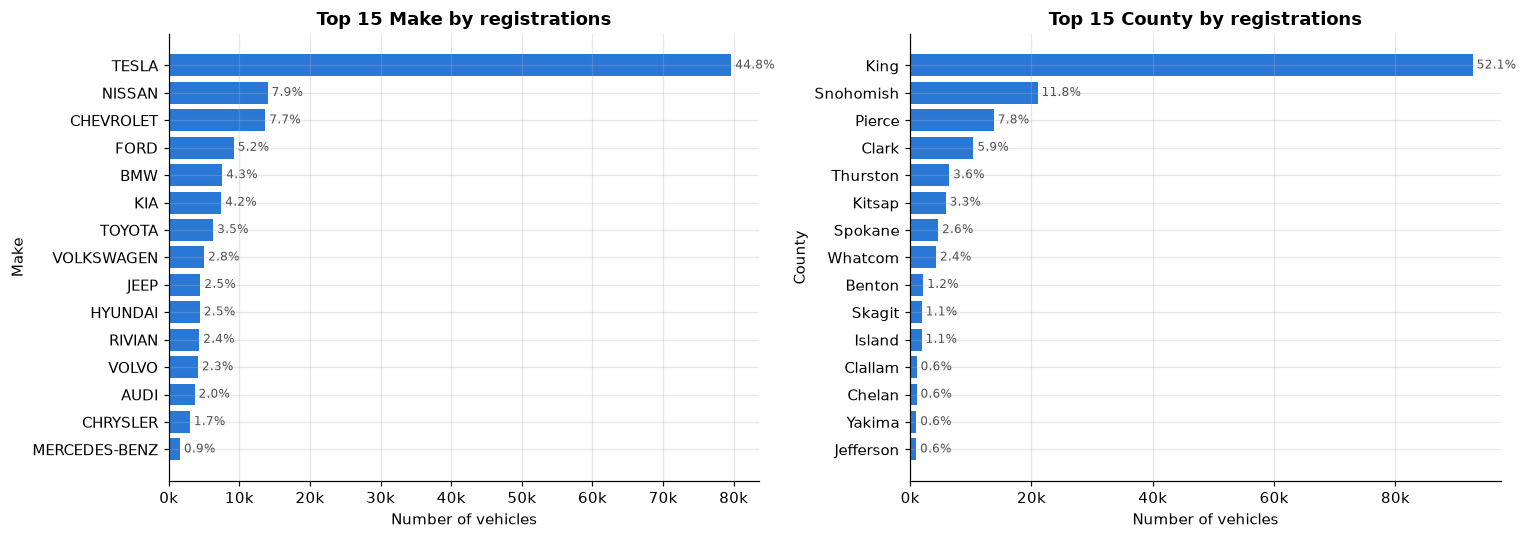

Top-5 makes cover 69.78% of rows; top-5 counties cover 81.17%.
Rare makes (<0.1% of rows): LAND ROVER, FISKER, ALFA ROMEO, AZURE DYNAMICS, TH!NK, GMC, BENTLEY, WHEEGO ELECTRIC CARS, ROLLS ROYCE


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, k in [(axes[0], "Make", 15), (axes[1], "County", 15)]:
    ts = top_share(df[col], k).iloc[::-1]
    ax.barh(ts.index.astype(str), ts["count"], color=SEQ_COLOR)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
    ax.set(title=f"Top {k} {col} by registrations", xlabel="Number of vehicles", ylabel=col)
    for y, (cnt, pct) in enumerate(zip(ts["count"], ts["pct"])):
        ax.text(cnt, y, f" {pct:.1f}%", va="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()

print(f"Top-5 makes cover {top_share(df['Make'], 5)['cum_pct'].iloc[-1]}% of rows; "
      f"top-5 counties cover {top_share(df['County'], 5)['cum_pct'].iloc[-1]}%.")
print("Rare makes (<0.1% of rows):", ", ".join(rare_categories(df["Make"]).index))

**`Electric Utility`.** Some addresses list several utilities separated by `|`, which matters for Q5/Q6.

In [20]:
n_util = utility_count(df["Electric Utility"])
print("Number of utilities listed per row:")
display(n_util.value_counts(dropna=False).sort_index().to_frame("rows"))

single_utils = df["Electric Utility"].str.split("|").explode().str.strip()
print(f"Distinct utilities after splitting on '|': {single_utils.nunique()}  "
      f"(vs {df['Electric Utility'].nunique()} raw strings)")
top_share(df["Electric Utility"], 10)

Number of utilities listed per row:


,rows
Electric Utility,
1,41732
2,31381
3,90074
4,357
5,13200
6,1117
<NA>,5


Distinct utilities after splitting on '|': 64  (vs 76 raw strings)


,count,pct,cum_pct
Electric Utility,,,
PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),65990,37.10,37.10
PUGET SOUND ENERGY INC,35882,20.17,57.27
CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),31381,17.64,74.91
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLARK COUNTY - (WA),10173,5.72,80.63
BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY,7828,4.40,85.03
PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY,4008,2.25,87.28
BONNEVILLE POWER ADMINISTRATION||AVISTA CORP||INLAND POWER & LIGHT COMPANY,2797,1.57,88.85
BONNEVILLE POWER ADMINISTRATION||PUD 1 OF SNOHOMISH COUNTY,1537,0.86,89.71
PACIFICORP,1306,0.73,90.44


> ✍️ **TODO (team):** comment on balance (BEV vs PHEV, Make concentration, King County dominance), on rare
categories that should be grouped into "Other", on out-of-state rows, and on how to handle
multi-utility strings.

### 2.5 Relationships

In [21]:
corr_df = df.assign(**{
    "Electric Range": df["Electric Range"].replace(0, np.nan),
    "Base MSRP": df["Base MSRP"].replace(0, np.nan),
})[["Model Year", "Electric Range", "Base MSRP"]]
print("Pearson (pairwise, placeholder zeros treated as NaN):")
display(corr_df.corr(method="pearson").round(3))
print("Spearman:")
display(corr_df.corr(method="spearman").round(3))
print("Pairwise non-null counts:")
display(corr_df.notna().astype(int).T @ corr_df.notna().astype(int))

Pearson (pairwise, placeholder zeros treated as NaN):


,Model Year,Electric Range,Base MSRP
Model Year,1.000,-0.060,-0.464
Electric Range,-0.060,1.000,0.406
Base MSRP,-0.464,0.406,1.000


Spearman:


,Model Year,Electric Range,Base MSRP
Model Year,1.000,-0.074,-0.593
Electric Range,-0.074,1.000,0.583
Base MSRP,-0.593,0.583,1.000


Pairwise non-null counts:


,Model Year,Electric Range,Base MSRP
Model Year,177866,85916,3344
Electric Range,85916,85916,3344
Base MSRP,3344,3344,3344


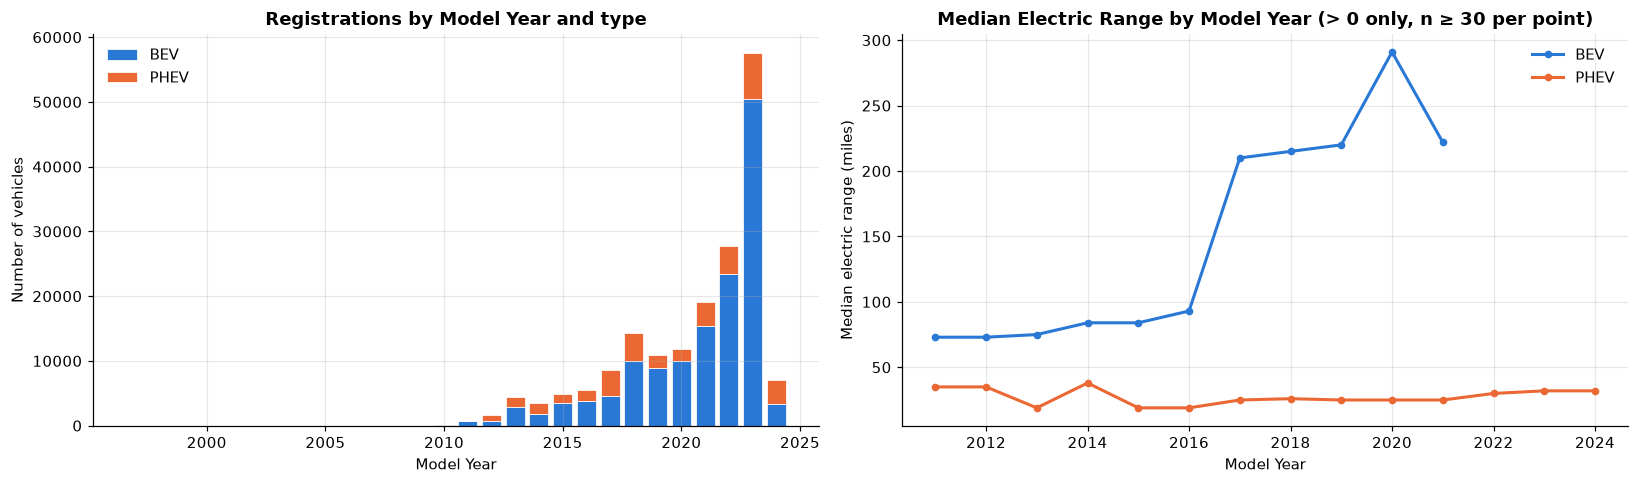

0,BEV,PHEV,pct_BEV
Model Year,,,
2015,3549,1295,73.3
2016,3734,1749,68.1
2017,4521,4041,52.8
2018,9958,4365,69.5
2019,8938,2002,81.7
2020,9978,1790,84.8
2021,15325,3807,80.1
2022,23446,4330,84.4
2023,50403,7184,87.5


In [22]:
type_short = df["Electric Vehicle Type"].str.extract(r"\((BEV|PHEV)\)")[0]
year_type = pd.crosstab(df["Model Year"], type_short)
year_type_pct = year_type.div(year_type.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bottom = np.zeros(len(year_type))
for t, c in TYPE_COLORS.items():
    axes[0].bar(year_type.index, year_type[t], bottom=bottom, color=c, label=t,
                width=0.8, edgecolor="white", linewidth=0.5)
    bottom += year_type[t].to_numpy()
axes[0].set(title="Registrations by Model Year and type", xlabel="Model Year",
            ylabel="Number of vehicles")
axes[0].legend(frameon=False)

grp = (df.loc[df["Electric Range"] > 0].assign(type=type_short)
         .groupby(["Model Year", "type"])["Electric Range"])
med = grp.median().where(grp.size() >= 30).unstack()  # hide medians based on < 30 vehicles
for t, c in TYPE_COLORS.items():
    axes[1].plot(med.index, med[t], marker="o", markersize=4, linewidth=2, color=c, label=t)
axes[1].set(title="Median Electric Range by Model Year (> 0 only, n ≥ 30 per point)", xlabel="Model Year",
            ylabel="Median electric range (miles)")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

year_type.assign(pct_BEV=year_type_pct["BEV"].round(1)).tail(10)

In [23]:
top_makes = df["Make"].value_counts().head(10).index
make_type = pd.crosstab(df.loc[df["Make"].isin(top_makes), "Make"], type_short, normalize="index") * 100
make_type.sort_values("BEV").round(1)

0,BEV,PHEV
Make,,
JEEP,0.0,100.0
TOYOTA,5.3,94.7
BMW,33.2,66.8
FORD,60.0,40.0
CHEVROLET,64.9,35.1
KIA,67.8,32.2
HYUNDAI,85.7,14.3
NISSAN,100.0,0.0
TESLA,100.0,0.0


Unparsed / missing locations: 9
Lon/lat range (WA rows):


,lon,lat
min,-124.62514,45.58359
max,-117.04437,48.99634


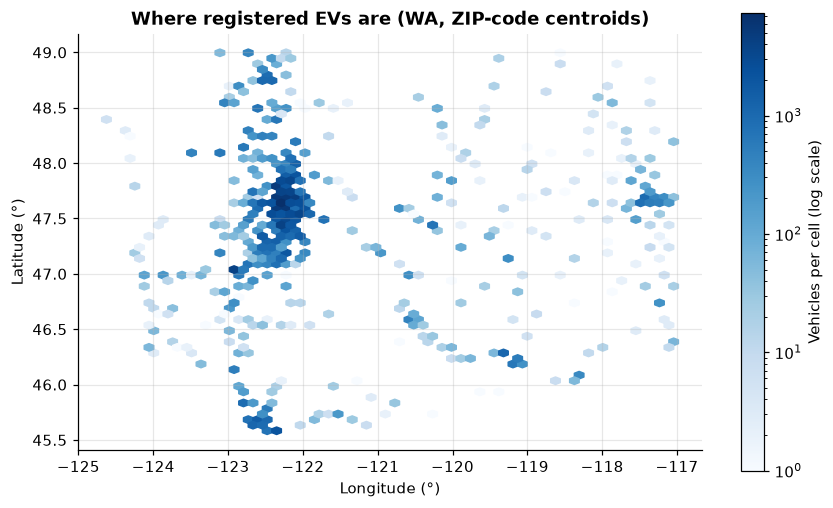

In [24]:
coords = parse_point(df["Vehicle Location"])
print("Unparsed / missing locations:", int(coords["lon"].isna().sum()))
wa = coords[df["State"].eq("WA")].join(type_short.rename("type"))
print("Lon/lat range (WA rows):")
display(wa[["lon", "lat"]].describe().loc[["min", "max"]])

fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(wa["lon"], wa["lat"], gridsize=60, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax, shrink=0.8, label="Vehicles per cell (log scale)")
ax.set(title="Where registered EVs are (WA, ZIP-code centroids)",
       xlabel="Longitude (°)", ylabel="Latitude (°)")
ax.set_aspect(1 / np.cos(np.deg2rad(47.5)))
plt.tight_layout()
plt.show()

In [25]:
# BEV share by county (counties with >= 500 vehicles)
county = (df.assign(is_bev=type_short.eq("BEV")).loc[df["State"].eq("WA")]
            .groupby("County").agg(n=("is_bev", "size"), bev_share=("is_bev", "mean")))
county = county[county["n"] >= 500].sort_values("bev_share")
county["bev_share"] = (county["bev_share"] * 100).round(1)
print(f"{len(county)} WA counties with >= 500 vehicles")
pd.concat([county.head(5), county.tail(5)])

23 WA counties with >= 500 vehicles


,n,bev_share
County,,
Lewis,739,56.8
Grays Harbor,625,65.8
Spokane,4586,68.3
Clallam,1058,68.6
Yakima,995,69.1
San Juan,942,78.2
Chelan,1047,78.8
Kittitas,623,80.3
King,92740,80.8


## 3. Summary & preprocessing plan

## 4. Questions